# Example 3.2 — Selectivity profile of a drug (imatinib)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:18Z
- **Contents:** 1 exchange · 6 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/3.2-compound-selectivity-profile-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 3.2-compound-selectivity-profile-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 3.2-compound-selectivity-profile-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/3.2-compound-selectivity-profile-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 3.2-compound-selectivity-profile-notebook-rerun.ipynb 3.2-compound-selectivity-profile-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Which human targets does imatinib bind below 100 nM?

In [ ]:
# Call 1 · search_compounds · ran 2026-11-24 04:55:18 UTC
await replay.call(1, 'search_compounds', {'query': 'imatinib'},
                  sha256='1f2a50bf819de48009ec8144d0b21eef4aca07d81ee80cd8718d9c5f2d42211d')

**Call 1** · `search_compounds` · recorded result · sha256 `1f2a50bf819d…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | KTUFNOKKBVMGRW-UHFFFAOYSA-N | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 493.26 | 1156 | 459 | Imatinib |
| 31341 | BDBM31341 | IMATINIB | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |  | 0 | 0 | IMATINIB |
| 50434581 | BDBM50434581 | imatinib-CD3 | KTUFNOKKBVMGRW-BMSJAHLVSA-N | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.58 | 2 | 2 | imatinib-CD3 |


In [ ]:
# Call 2 · find_targets_for_compound · ran 2026-11-24 04:55:18 UTC
await replay.call(2, 'find_targets_for_compound', {'monomerid': 13530, 'max_value_nm': 100},
                  sha256='f715226daf99d84a995f4fb445e5699f4698926d4cf61f5dea12b2d73e7c7cd5')

**Call 2** · `find_targets_for_compound` · recorded result · sha256 `f715226daf99…`

_35 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51506159 | IC50 | = | 0.06 | nM | 10.22 | 13530 | Gleevec | 188 |  | Receptor tyrosine-protein kinase erbB-2 | P04626 | Homo sapiens |  |  | ChEMBL\_2261296 (CHEMBL5216307) | 35696863 | 10.1016/j.ejmech.2022.114502 | 2022 | 1 |
| 51506157 | IC50 | = | 0.11 | nM | 9.96 | 13530 | Gleevec | 520 |  | Epidermal growth factor receptor | P00533 | Homo sapiens |  |  | ChEMBL\_2261295 (CHEMBL5216306) | 35696863 | 10.1016/j.ejmech.2022.114502 | 2022 | 1 |
| 58107 | Kd | = | 0.7 | nM | 9.15 | 13530 | Gleevec | 3993 |  | Epithelial discoidin domain-containing receptor 1 | Q08345 | Homo sapiens | 7.4 | 298.15 | Kinase Inhibitor Selectivity Profiling Assay | aid1433 |  | 2008 | 6 |
| 51232598 | Kd | = | 1 | nM | 9 | 13530 | Gleevec | 5221 |  | Tyrosine-protein kinase ABL1 | P00519 | Homo sapiens |  |  | ChEMBL\_1821228 (CHEMBL4320888) | 30807144 | 10.1021/acs.jmedchem.8b01925 | 2019 | 38 |
| 50160997 | IC50 | = | 1.1 | nM | 8.96 | 13530 | Gleevec |  | 261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  |  |  | ChEMBL\_614493 (CHEMBL1110561) | 20166671 | 10.1021/jm901132v | 2010 | 19 |
| 334877 | Kd | = | 1.5 | nM | 8.82 | 13530 | Gleevec | 7838 |  | Tyrosine-protein kinase ABL1 \[229-512\] | P00519\[229-512\] | Homo sapiens |  |  | Kinome-Wide Inhibitor Profiling | 26895387 | 10.1021/acschembio.5b01018 | 2016 | 2 |
| 24176 | Kd | = | 2 | nM | 8.7 | 13530 | Gleevec | 1385 |  | Tyrosine-protein kinase ABL1 \[201-500\] | P00519\[201-500\] | Homo sapiens | 7.4 | 298.15 | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 189434 | Ki | = | 2 | nM | 8.7 | 13530 | Gleevec | 5778 |  | Platelet-derived growth factor receptor alpha | P16234 | Homo sapiens |  |  |  | 16492761 | 10.1073/pnas.0511292103 | 2006 | 13 |
| 24191 | Kd | = | 3 | nM | 8.52 | 13530 | Gleevec | 1394 |  | Mast/stem cell growth factor receptor Kit \[N822K\] | P10721\[N822K\] | Homo sapiens |  |  | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 189436 | Ki | = | 3 | nM | 8.52 | 13530 | Gleevec | 575 |  | Platelet-derived growth factor receptor beta | P09619 | Homo sapiens |  |  |  | 16492761 | 10.1073/pnas.0511292103 | 2006 | 6 |
| 24180 | Kd | = | 10 | nM | 8 | 13530 | Gleevec | 1389 |  | Tyrosine-protein kinase ABL1 \[201-500,M351T\] | P00519\[201-500,M351T\] | Homo sapiens | 7.4 | 298.15 | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 65729 | Kd | = | 10 | nM | 8 | 13530 | Gleevec | 50001306 |  | Tyrosine-protein kinase ABL2 | P42684 | Homo sapiens |  |  | Kinase Inhibitor Selectivity Profiling Assay | aid1433 |  | 2008 | 6 |
| 51232593 | Kd | = | 10 | nM | 8 | 13530 | Gleevec | 879 |  | Macrophage colony-stimulating factor 1 receptor | P07333 | Homo sapiens |  |  | ChEMBL\_1821226 (CHEMBL4320886) | 30807144 | 10.1021/acs.jmedchem.8b01925 | 2019 | 4 |
| 50589673 | IC50 | = | 10.8 | nM | 7.97 | 13530 | Gleevec | 50001750 |  | Tyrosine-protein kinase ABL1 | P00520 | Mus musculus |  |  | ChEMBL\_647651 (CHEMBL1220002) | 20621496 | 10.1016/j.bmc.2010.05.063 | 2010 | 1 |
| 50195818 | Kd | = | 13 | nM | 7.89 | 13530 | Gleevec | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | ChEMBL\_774266 (CHEMBL1908483) | 22037378 | 10.1038/nbt.1990 | 2011 | 27 |
| 58126 | Kd | = | 15 | nM | 7.82 | 13530 | Gleevec | 3995 |  | Discoidin domain-containing receptor 2 \[A642S\] | Q16832\[A642S\] | Homo sapiens | 7.4 | 298.15 | Kinase Inhibitor Selectivity Profiling Assay | aid1433 |  | 2008 | 1 |
| 50673776 | Kd | = | 15 | nM | 7.82 | 13530 | Gleevec | 5709 |  | Discoidin domain-containing receptor 2 | Q16832 | Homo sapiens |  |  | ChEMBL\_774257 (CHEMBL1908474) | 22037378 | 10.1038/nbt.1990 | 2011 | 2 |
| 24177 | Kd | = | 20 | nM | 7.7 | 13530 | Gleevec | 1386 |  | Tyrosine-protein kinase ABL1 \[201-500,Q252H\] | P00519\[201-500,Q252H\] | Homo sapiens | 7.4 | 298.15 | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 24181 | Kd | = | 20 | nM | 7.7 | 13530 | Gleevec | 1390 |  | Tyrosine-protein kinase ABL1 \[201-500,F359V\] | P00519\[201-500,F359V\] | Homo sapiens | 7.4 | 298.15 | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 24192 | Kd | = | 20 | nM | 7.7 | 13530 | Gleevec | 1395 |  | Mast/stem cell growth factor receptor Kit \[V559D\] | P10721\[V559D\] | Homo sapiens |  |  | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 126580 | IC50 | = | 27 | nM | 7.57 | 13530 | Gleevec | 4453 |  | Tyrosine-protein kinase ABL1 \[1-999,Q252H\] | P00519\[1-999,Q252H\] | Homo sapiens | 7.5 |  | Biochemcial Assay  | 16873026 | 10.1016/j.chembiol.2006.05.015 | 2006 | 1 |
| 50513152 | Ki | = | 30.2 | nM | 7.52 | 13530 | Gleevec | 1193 |  | Carbonic anhydrase 2 | P00918 | Homo sapiens |  |  | ChEMBL\_579711 (CHEMBL1053952) | 19527930 | 10.1016/j.bmcl.2009.06.002 | 2009 | 1 |
| 50513151 | Ki | = | 31.9 | nM | 7.5 | 13530 | Gleevec | 1192 |  | Carbonic anhydrase 1 | P00915 | Homo sapiens |  |  | ChEMBL\_579710 (CHEMBL1053951) | 19527930 | 10.1016/j.bmcl.2009.06.002 | 2009 | 1 |
| 51519669 | IC50 | = | 38 | nM | 7.42 | 13530 | Gleevec | 50001198 |  | Breakpoint cluster region protein | Q6PAJ1 | Mus musculus |  |  | ChEMBL\_2284540 | 30243589 | 10.1016/j.bmcl.2018.09.016 | 2018 | 1 |
| 50552519 | Ki | = | 39 | nM | 7.41 | 13530 | Gleevec | 5286 |  | Ribosyldihydronicotinamide dehydrogenase \[quinone\] | P16083 | Homo sapiens |  |  | ChEMBL\_1634419 (CHEMBL3877211) | 28280261 | 10.1038/nrd.2016.266 | 2017 | 3 |
| 24178 | Kd | = | 40 | nM | 7.4 | 13530 | Gleevec | 1387 |  | Tyrosine-protein kinase ABL1 \[201-500,Y253F\] | P00519\[201-500,Y253F\] | Homo sapiens | 7.4 | 298.15 | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 65558 | Kd | = | 40 | nM | 7.4 | 13530 | Gleevec | 507 |  | Tyrosine-protein kinase Lck | P06239 | Homo sapiens |  |  | Kinase Inhibitor Selectivity Profiling Assay | aid1433 |  | 2008 | 5 |
| 50488791 | IC50 | = | 40 | nM | 7.4 | 13530 | Gleevec |  | 50000208 | Tyrosine-protein kinase ABL1/ABL2 |  |  |  |  | ChEMBL\_226185 (CHEMBL846551) | 12951113 | 10.1016/s0960-894x(03)00553-5 | 2003 | 1 |
| 51040772 | IC50 | = | 40 | nM | 7.4 | 13530 | Gleevec | 50006151 |  | Multidrug and toxin extrusion protein 1 | Q96FL8 | Homo sapiens |  |  | ChEMBL\_934312 (CHEMBL2320298) | 23241029 | 10.1021/jm301302s | 2013 | 2 |
| 50206651 | IC50 | = | 50 | nM | 7.3 | 13530 | Gleevec |  | 50000008 | Platelet-derived growth factor receptor alpha/beta |  |  |  |  | ChEMBL\_321279 (CHEMBL857667) | 16220969 | 10.1021/jm058225d | 2005 | 2 |
| 51519671 | IC50 | = | 50 | nM | 7.3 | 13530 | Gleevec | 633 |  | Platelet-derived growth factor receptor beta | P05622 | Mus musculus |  |  | ChEMBL\_2284541 | 30243589 | 10.1016/j.bmcl.2018.09.016 | 2018 | 1 |
| 24188 | Kd | = | 60 | nM | 7.22 | 13530 | Gleevec | 1391 |  | Tyrosine-protein kinase ABL1 \[201-500,H396P\] | P00519\[201-500,H396P\] | Homo sapiens |  |  | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |
| 50513159 | Ki | = | 75.7 | nM | 7.12 | 13530 | Gleevec | 1233 |  | Carbonic anhydrase 9 | Q16790 | Homo sapiens |  |  | ChEMBL\_579718 (CHEMBL1053959) | 19527930 | 10.1016/j.bmcl.2009.06.002 | 2009 | 1 |
| 50513163 | Ki | = | 78 | nM | 7.11 | 13530 | Gleevec | 50004142 |  | Carbonic anhydrase 15 | Q99N23 | Mus musculus |  |  | ChEMBL\_579804 (CHEMBL1059705) | 19527930 | 10.1016/j.bmcl.2009.06.002 | 2009 | 1 |
| 24179 | Kd | = | 100 | nM | 7 | 13530 | Gleevec | 1388 |  | Tyrosine-protein kinase ABL1 \[201-500,E255K\] | P00519\[201-500,E255K\] | Homo sapiens | 7.4 | 298.15 | Kinase Assay and Binding Constant Measurement | 16046538 | 10.1073/pnas.0504952102 | 2005 | 1 |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:18 UTC
sql = """
    SELECT polymerid, target_name, uniprot, count(*) AS n, round(median(p_affinity),2) AS median_p_affinity, count(*) FILTER (WHERE value <= 100 AND relation IN ('=','<')) AS n_le_100nM FROM activity WHERE monomerid = 13530 AND organism = 'Homo sapiens' AND uniprot_raw = uniprot AND polymerid IN (188,520,3993,5221,5778,575,50001306,879,359,5709,1193,1192,5286,507,50006151,1233) GROUP BY polymerid, target_name, uniprot ORDER BY n DESC, polymerid
    
"""
await replay.call(3, 'run_sql', {'sql': sql},
                  sha256='2f3167242e5bd3c3045353a5f735f31d23c50b9bc1b7a96e11fbacfef430c7f0')

**Call 3** · `run_sql` · recorded result · sha256 `2f3167242e5b…`

_16 rows_

| polymerid | target_name | uniprot | n | median_p_affinity | n_le_100nM |
| --- | --- | --- | --- | --- | --- |
| 5221 | Tyrosine-protein kinase ABL1 | P00519 | 85 | 6.77 | 38 |
| 359 | Mast/stem cell growth factor receptor Kit | P10721 | 52 | 7 | 27 |
| 520 | Epidermal growth factor receptor | P00533 | 25 | 5 | 1 |
| 5778 | Platelet-derived growth factor receptor alpha | P16234 | 17 | 7.51 | 13 |
| 575 | Platelet-derived growth factor receptor beta | P09619 | 10 | 7.35 | 6 |
| 50001306 | Tyrosine-protein kinase ABL2 | P42684 | 10 | 7.95 | 6 |
| 507 | Tyrosine-protein kinase Lck | P06239 | 9 | 7.21 | 5 |
| 3993 | Epithelial discoidin domain-containing receptor 1 | Q08345 | 9 | 7.37 | 6 |
| 879 | Macrophage colony-stimulating factor 1 receptor | P07333 | 7 | 7.72 | 4 |
| 5709 | Discoidin domain-containing receptor 2 | Q16832 | 5 | 6.85 | 2 |
| 5286 | Ribosyldihydronicotinamide dehydrogenase \[quinone\] | P16083 | 4 | 7.23 | 3 |
| 188 | Receptor tyrosine-protein kinase erbB-2 | P04626 | 3 | 5 | 1 |
| 50006151 | Multidrug and toxin extrusion protein 1 | Q96FL8 | 3 | 7.3 | 2 |
| 1192 | Carbonic anhydrase 1 | P00915 | 1 | 7.5 | 1 |
| 1193 | Carbonic anhydrase 2 | P00918 | 1 | 7.52 | 1 |
| 1233 | Carbonic anhydrase 9 | Q16790 | 1 | 7.12 | 1 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:55:18 UTC
sql = """
    SELECT polymerid, target_name, affinity_type, count(*) AS n, count(*) FILTER (WHERE relation = '=') AS n_exact, median(value) FILTER (WHERE relation = '=') AS median_exact_nm, min(value) FILTER (WHERE relation IN ('=','<')) AS best_nm, count(*) FILTER (WHERE relation = '>') AS n_greater FROM activity WHERE monomerid = 13530 AND organism = 'Homo sapiens' AND uniprot_raw = uniprot AND polymerid IN (188,520,3993,5221,5778,575,50001306,879,359,5709,1193,1192,5286,507,50006151,1233) GROUP BY polymerid, target_name, affinity_type ORDER BY polymerid, affinity_type
    
"""
await replay.call(4, 'run_sql', {'sql': sql},
                  sha256='1d7536374c4e0043e8f025f44f1091dfbb67a02a52d95822d47feb8ce8d509b9')

**Call 4** · `run_sql` · recorded result · sha256 `1d7536374c4e…`

_36 rows_

| polymerid | target_name | affinity_type | n | n_exact | median_exact_nm | best_nm | n_greater |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 188 | Receptor tyrosine-protein kinase erbB-2 | IC50 | 1 | 1 | 0.06 | 0.06 | 0 |
| 188 | Receptor tyrosine-protein kinase erbB-2 | Kd | 2 | 0 |  |  | 2 |
| 359 | Mast/stem cell growth factor receptor Kit | EC50 | 1 | 1 | 100 | 100 | 0 |
| 359 | Mast/stem cell growth factor receptor Kit | IC50 | 28 | 28 | 159.5 | 16 | 0 |
| 359 | Mast/stem cell growth factor receptor Kit | Kd | 16 | 16 | 43 | 13 | 0 |
| 359 | Mast/stem cell growth factor receptor Kit | Ki | 7 | 7 | 15000 | 14 | 0 |
| 507 | Tyrosine-protein kinase Lck | IC50 | 3 | 3 | 320 | 160 | 0 |
| 507 | Tyrosine-protein kinase Lck | Kd | 5 | 5 | 40 | 40 | 0 |
| 507 | Tyrosine-protein kinase Lck | Ki | 1 | 1 | 6893 | 6893 | 0 |
| 520 | Epidermal growth factor receptor | IC50 | 2 | 1 | 0.11 | 0.11 | 1 |
| 520 | Epidermal growth factor receptor | Kd | 23 | 3 | 7600 | 7600 | 20 |
| 575 | Platelet-derived growth factor receptor beta | IC50 | 5 | 5 | 240 | 72 | 0 |
| 575 | Platelet-derived growth factor receptor beta | Kd | 4 | 4 | 14 | 14 | 0 |
| 575 | Platelet-derived growth factor receptor beta | Ki | 1 | 1 | 3 | 3 | 0 |
| 879 | Macrophage colony-stimulating factor 1 receptor | IC50 | 3 | 3 | 960 | 291 | 0 |
| 879 | Macrophage colony-stimulating factor 1 receptor | Kd | 4 | 4 | 15 | 10 | 0 |
| 1192 | Carbonic anhydrase 1 | Ki | 1 | 1 | 31.9 | 31.9 | 0 |
| 1193 | Carbonic anhydrase 2 | Ki | 1 | 1 | 30.2 | 30.2 | 0 |
| 1233 | Carbonic anhydrase 9 | Ki | 1 | 1 | 75.7 | 75.7 | 0 |
| 3993 | Epithelial discoidin domain-containing receptor 1 | IC50 | 5 | 5 | 337 | 43 | 0 |
| 3993 | Epithelial discoidin domain-containing receptor 1 | Kd | 4 | 4 | 0.7 | 0.7 | 0 |
| 5221 | Tyrosine-protein kinase ABL1 | EC50 | 1 | 1 | 70 | 70 | 0 |
| 5221 | Tyrosine-protein kinase ABL1 | IC50 | 43 | 39 | 300 | 20 | 4 |
| 5221 | Tyrosine-protein kinase ABL1 | Kd | 35 | 32 | 35 | 1 | 3 |
| 5221 | Tyrosine-protein kinase ABL1 | Ki | 6 | 6 | 25 | 13 | 0 |
| 5286 | Ribosyldihydronicotinamide dehydrogenase \[quinone\] | IC50 | 3 | 3 | 82 | 43 | 0 |
| 5286 | Ribosyldihydronicotinamide dehydrogenase \[quinone\] | Ki | 1 | 1 | 39 | 39 | 0 |
| 5709 | Discoidin domain-containing receptor 2 | IC50 | 3 | 3 | 675 | 141 | 0 |
| 5709 | Discoidin domain-containing receptor 2 | Kd | 2 | 2 | 15 | 15 | 0 |
| 5778 | Platelet-derived growth factor receptor alpha | EC50 | 1 | 1 | 90 | 90 | 0 |
| 5778 | Platelet-derived growth factor receptor alpha | IC50 | 12 | 12 | 71.5 | 2 | 0 |
| 5778 | Platelet-derived growth factor receptor alpha | Kd | 3 | 3 | 31 | 31 | 0 |
| 5778 | Platelet-derived growth factor receptor alpha | Ki | 1 | 1 | 2 | 2 | 0 |
| 50001306 | Tyrosine-protein kinase ABL2 | IC50 | 4 | 4 | 1000 | 272 | 0 |
| 50001306 | Tyrosine-protein kinase ABL2 | Kd | 6 | 6 | 10 | 10 | 0 |
| 50006151 | Multidrug and toxin extrusion protein 1 | IC50 | 3 | 3 | 50 | 40 | 0 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:55:18 UTC
sql = """
    SELECT polymerid, target_name, affinity_type, relation, value, source_id, year, ki_result_id FROM activity WHERE monomerid = 13530 AND polymerid IN (188,520,1192,1193,1233) AND (affinity_type IN ($$IC50$$,$$Ki$$)) ORDER BY polymerid, value, ki_result_id
    
"""
await replay.call(5, 'run_sql', {'sql': sql},
                  sha256='d188a9317e6a8c54ad089a74aae1a109771347e5e75f3880015a417bc49b170a')

**Call 5** · `run_sql` · recorded result · sha256 `d188a9317e6a…`

_6 rows_

| polymerid | target_name | affinity_type | relation | value | source_id | year | ki_result_id |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 188 | Receptor tyrosine-protein kinase erbB-2 | IC50 | = | 0.06 | 35696863 | 2022 | 51506159 |
| 520 | Epidermal growth factor receptor | IC50 | = | 0.11 | 35696863 | 2022 | 51506157 |
| 520 | Epidermal growth factor receptor | IC50 | \> | 100000 |  | 1997 | 50484525 |
| 1192 | Carbonic anhydrase 1 | Ki | = | 31.9 | 19527930 | 2009 | 50513151 |
| 1193 | Carbonic anhydrase 2 | Ki | = | 30.2 | 19527930 | 2009 | 50513152 |
| 1233 | Carbonic anhydrase 9 | Ki | = | 75.7 | 19527930 | 2009 | 50513159 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:18 UTC
sql = """
    SELECT polymerid, affinity_type, relation, value, source_id, year, assay_name, ki_result_id FROM activity WHERE monomerid = 13530 AND polymerid IN (359,5221) AND affinity_type = $$Ki$$ ORDER BY polymerid, value, ki_result_id
    
"""
await replay.call(6, 'run_sql', {'sql': sql},
                  sha256='80a39dff3204e20664eb107cac6d2aad2af326f6ba7c1b5b564fa599dd090721')

**Call 6** · `run_sql` · recorded result · sha256 `80a39dff3204…`

_13 rows_

| polymerid | affinity_type | relation | value | source_id | year | assay_name | ki_result_id |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 359 | Ki | = | 14 | 16492761 | 2006 |  | 189446 |
| 359 | Ki | = | 30.7 | US10906896-B2 | 2021 | Kinase Assay | 1000362 |
| 359 | Ki | = | 14000 | aid1433 | 2008 | Kinase Inhibitor Selectivity Profiling Assay | 62794 |
| 359 | Ki | = | 15000 | aid1433 | 2008 | Kinase Inhibitor Selectivity Profiling Assay | 62877 |
| 359 | Ki | = | 71000 | aid1433 | 2008 | Kinase Inhibitor Selectivity Profiling Assay | 62856 |
| 359 | Ki | = | 820000 | aid1433 | 2008 | Kinase Inhibitor Selectivity Profiling Assay | 62817 |
| 359 | Ki | = | 2.9e+06 | aid1433 | 2008 | Kinase Inhibitor Selectivity Profiling Assay | 62837 |
| 5221 | Ki | = | 13 | 18078752 | 2008 |  | 189869 |
| 5221 | Ki | = | 13 | 18342402 | 2008 | ChEMBL\_518628 (CHEMBL962773) | 50412055 |
| 5221 | Ki | = | 13 | 21443205 | 2011 | ChEMBL\_745920 (CHEMBL1776290) | 50638776 |
| 5221 | Ki | = | 37 | 16783341 | 2006 | ChEMBL\_660971 (CHEMBL1249638) | 50594513 |
| 5221 | Ki | = | 298 | 16492761 | 2006 |  | 189444 |
| 5221 | Ki | = | 7000 | 16783341 | 2006 | ChEMBL\_660972 (CHEMBL1249639) | 50165387 |


**Figure 1: Imatinib: human wild-type targets with a measurement at or below 100 nM.** _(as recorded)_

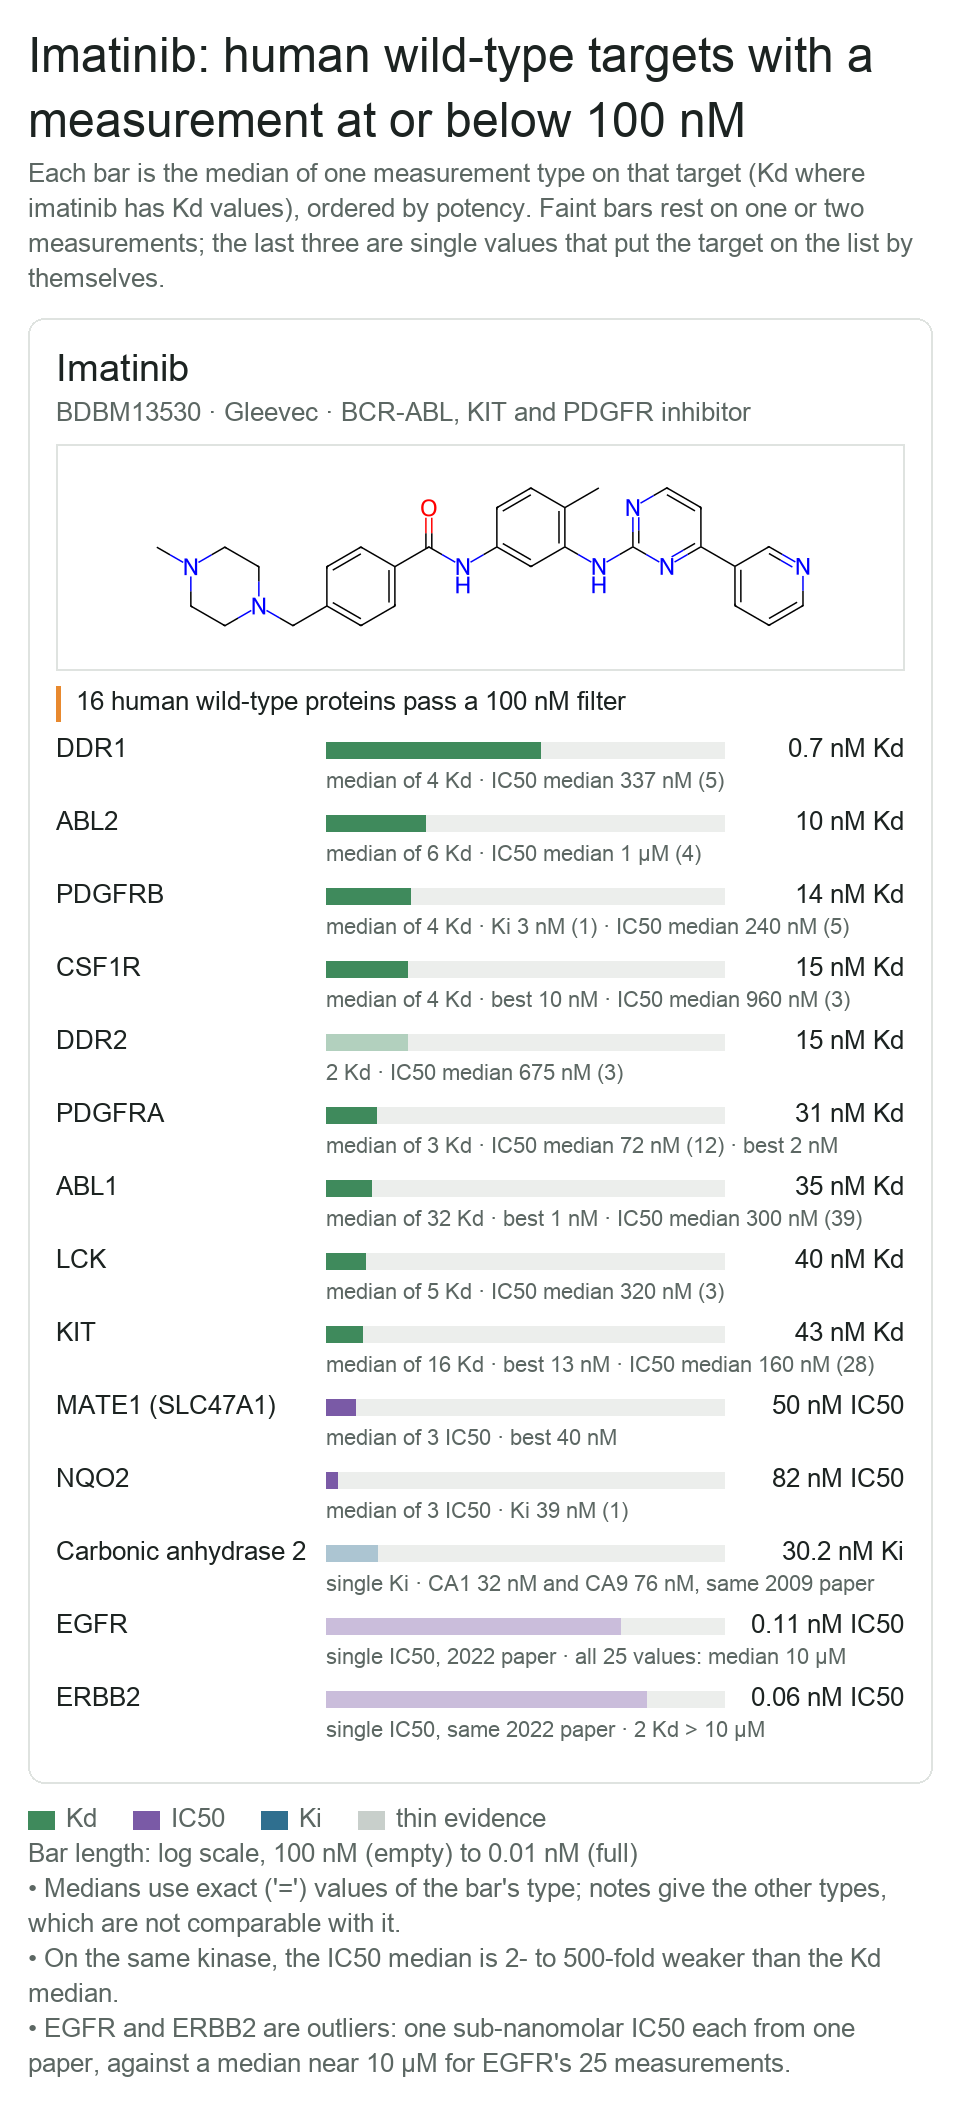

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Imatinib: human wild-type targets with a measurement at or below 100 nM',
    'compounds': [
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
            'title': 'Imatinib',
            'subtitle': 'BDBM13530 · Gleevec · BCR-ABL, KIT and PDGFR inhibitor',
            'caption': '16 human wild-type proteins pass a 100 nM filter',
            'bars': [
                {
                    'label': 'DDR1',
                    'value_nm': 0.7,
                    'type': 'Kd',
                    'note': 'median of 4 Kd · IC50 median 337 nM (5)',
                },
                {
                    'label': 'ABL2',
                    'value_nm': 10.0,
                    'type': 'Kd',
                    'note': 'median of 6 Kd · IC50 median 1 µM (4)',
                },
                {
                    'label': 'PDGFRB',
                    'value_nm': 14.0,
                    'type': 'Kd',
                    'note': 'median of 4 Kd · Ki 3 nM (1) · IC50 median 240 nM (5)',
                },
                {
                    'label': 'CSF1R',
                    'value_nm': 15.0,
                    'type': 'Kd',
                    'note': 'median of 4 Kd · best 10 nM · IC50 median 960 nM (3)',
                },
                {
                    'label': 'DDR2',
                    'value_nm': 15.0,
                    'type': 'Kd',
                    'note': '2 Kd · IC50 median 675 nM (3)',
                    'faint': True,
                },
                {
                    'label': 'PDGFRA',
                    'value_nm': 31.0,
                    'type': 'Kd',
                    'note': 'median of 3 Kd · IC50 median 72 nM (12) · best 2 nM',
                },
                {
                    'label': 'ABL1',
                    'value_nm': 35.0,
                    'type': 'Kd',
                    'note': 'median of 32 Kd · best 1 nM · IC50 median 300 nM (39)',
                },
                {
                    'label': 'LCK',
                    'value_nm': 40.0,
                    'type': 'Kd',
                    'note': 'median of 5 Kd · IC50 median 320 nM (3)',
                },
                {
                    'label': 'KIT',
                    'value_nm': 43.0,
                    'type': 'Kd',
                    'note': 'median of 16 Kd · best 13 nM · IC50 median 160 nM (28)',
                },
                {
                    'label': 'MATE1 (SLC47A1)',
                    'value_nm': 50.0,
                    'type': 'IC50',
                    'note': 'median of 3 IC50 · best 40 nM',
                },
                {
                    'label': 'NQO2',
                    'value_nm': 82.0,
                    'type': 'IC50',
                    'note': 'median of 3 IC50 · Ki 39 nM (1)',
                },
                {
                    'label': 'Carbonic anhydrase 2',
                    'value_nm': 30.2,
                    'type': 'Ki',
                    'note': 'single Ki · CA1 32 nM and CA9 76 nM, same 2009 paper',
                    'faint': True,
                },
                {
                    'label': 'EGFR',
                    'value_nm': 0.11,
                    'type': 'IC50',
                    'note': 'single IC50, 2022 paper · all 25 values: median 10 µM',
                    'faint': True,
                },
                {
                    'label': 'ERBB2',
                    'value_nm': 0.06,
                    'type': 'IC50',
                    'note': 'single IC50, same 2022 paper · 2 Kd > 10 µM',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 1,
    'description': 'Each bar is the median of one measurement type on that target (Kd where imatinib has Kd values), ordered by potency. Faint bars rest on one or two measurements; the last three are single values that put the target on the list by themselves.',
    'notes': [
        "Medians use exact ('=') values of the bar's type; notes give the other types, which are not comparable with it.",
        'On the same kinase, the IC50 median is 2- to 500-fold weaker than the Kd median.',
        "EGFR and ERBB2 are outliers: one sub-nanomolar IC50 each from one paper, against a median near 10 µM for EGFR's 25 measurements.",
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Asked for "targets below 100 nM", BindingDB returns 35 target records where imatinib (BDBM13530) has at least one Ki, Kd, IC50 or EC50 ≤ 100 nM. Only 16 of those are distinct human wild-type proteins:

| Kind of target record | Count | Examples |
|---|---|---|
| Human wild-type protein | 16 | ABL1, KIT, PDGFR-alpha/beta, DDR1, CSF1R, LCK |
| Mutant or truncated construct of a human protein | 12 | ABL1 [201-500, E255K], ABL1 [229-512], KIT [V559D], KIT [N822K], DDR2 [A642S] |
| Non-human protein | 4 | mouse ABL1, mouse BCR, mouse PDGFR-beta, mouse carbonic anhydrase 15 |
| Protein complex | 3 | BCR-ABL fusion, ABL1/ABL2, PDGFR-alpha/beta |

BindingDB stores each mutant, kinase-domain construct and species as its own target. A selectivity profile therefore looks longer than the list of distinct proteins: ABL1 alone appears as 9 records in addition to wild-type ABL1.

**The 16 human wild-type targets** are in the grid below, one bar per target. Each bar is the median of one measurement type, Kd wherever imatinib has Kd values on that target, because mixing Kd with cellular IC50s in one median would make the targets incomparable. The note under each bar gives the number of values, the best one, and the median of the other types. The three carbonic anhydrases share one bar, and the last three bars are single measurements.

The well-supported targets are the expected ones: ABL1 and ABL2, KIT, PDGFR-alpha and -beta, DDR1 and DDR2, CSF1R and LCK, all with Kd medians between 0.7 and 43 nM. Imatinib also hits non-kinases: NQO2 and the drug transporter MATE1 (three IC50s each, medians 82 and 50 nM), and carbonic anhydrases 1, 2 and 9, whose values are single Ki measurements from one 2009 paper (PMID 19527930).

The measurement type matters as much as the target. On the same kinase, imatinib's IC50 median is 2- to 500-fold weaker than its Kd median: ABL1 has a Kd median of 35 nM over 32 values but an IC50 median of 300 nM over 39, and DDR1 goes from 0.7 nM (Kd) to 337 nM (IC50). Ki values can mislead too: KIT's seven Ki values have a median of 15 µM, because five of them come from one PubChem kinase profiling screen (aid1433) with values of 14 µM to 2.9 mM, while the two literature Ki values are 14 and 31 nM. ABL1's six Ki values have a median of 25 nM. Taken over all types together, as a plain median of pAffinity, ABL1 comes out at only 6.8 (about 170 nM) across 85 measurements, and KIT at 7.0 across 52.

**Lesson:** a threshold filter tests the best value, not the typical one. max_value_nm = 100 keeps a target if any one measurement passes. EGFR and ERBB2 make the list from one sub-nanomolar IC50 each, from one 2022 paper (PMID 35696863); they are the faint bars at the bottom of the grid. EGFR's 25 measurements have a median of 10 µM, and ERBB2's two Kd values are both above 10 µM, so imatinib does not meaningfully inhibit either. ABL1 is the opposite case: it is imatinib's main target, yet only 38 of its 85 values are ≤ 100 nM, because cellular IC50s run weaker than biochemical Kd and Ki. Before you call something a target, check how many measurements support it, of which type, and what their median is.

### How this was answered

- **search_compounds** with query "imatinib": BDBM13530 (Gleevec), the record with imatinib's measurements (also found in Example 1.1).
- **find_targets_for_compound** with monomerid 13530, max_value_nm 100: every target with at least one measurement ≤ 100 nM, one row per target with its best value.
- **run_sql** on the activity table: for the human wild-type targets (UniProt accession without mutation brackets), the number of measurements, the median pAffinity and the count ≤ 100 nM; then the same broken down by affinity type, with the median of the exact ('=') values of each type; then the sources of the EGFR, ERBB2 and carbonic anhydrase values, and of the KIT and ABL1 Ki values.
- **draw_structure_grid**: one card for imatinib with a bar per target, using the Kd median where there is one, faint bars for targets with one or two measurements.

### Try next

- "Compare imatinib, nilotinib, dasatinib and bosutinib across kinases." (Example 5.2)
- "Show me the assay details behind the most potent gefitinib measurement on EGFR." (Example 3.4)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 6 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 3.2 — Selectivity profile of a drug (imatinib), 2026-11-23, with claude-opus-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```